<a href="https://colab.research.google.com/github/GAJIN-S/ML/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
!pip install -q datasets tensorflow keras-tuner scikit-learn pandas matplotlib seaborn

Import libraries and configure seed

In [38]:
import numpy as np
import pandas as pd
import tensorflow as tf
import keras_tuner as kt
import random
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import time

from datasets import load_dataset

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras Tuner:", kt.__version__)

TensorFlow: 2.21.0
Keras Tuner: 1.4.8


Load dataset

In [39]:
dataset = load_dataset(
    "Sp1786/multiclass-sentiment-analysis-dataset"
)

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(train_df.head())

Train: (31232, 4)
Validation: (5205, 4)
Test: (5206, 4)
      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative


In [28]:
train_df = ds["train"].to_pandas()

val_key = "validation" if "validation" in ds else "val"

val_df = ds[val_key].to_pandas()
test_df = ds["test"].to_pandas()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(train_df.head())

Train: (31232, 4)
Validation: (5205, 4)
Test: (5206, 4)
      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative


Data preprocessing

In [40]:
# Remove missing values
train_df = train_df.dropna(subset=["text", "label"])
val_df = val_df.dropna(subset=["text", "label"])
test_df = test_df.dropna(subset=["text", "label"])

# Convert text to string
train_text = train_df["text"].astype(str).tolist()
val_text = val_df["text"].astype(str).tolist()
test_text = test_df["text"].astype(str).tolist()

# Encode labels
encoder = LabelEncoder()

y_train = encoder.fit_transform(train_df["label"])
y_val = encoder.transform(val_df["label"])
y_test = encoder.transform(test_df["label"])

num_classes = len(encoder.classes_)

print("Classes:", encoder.classes_)
print("Number of classes:", num_classes)

Classes: [0 1 2]
Number of classes: 3


Tokenization and padding

In [41]:
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train_text)

X_train_seq = tokenizer.texts_to_sequences(train_text)
X_val_seq = tokenizer.texts_to_sequences(val_text)
X_test_seq = tokenizer.texts_to_sequences(test_text)

X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

VOCAB_SIZE = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Vocabulary:", VOCAB_SIZE)

Training: (31232, 100)
Validation: (5205, 100)
Testing: (5205, 100)
Vocabulary: 20000


Random Search AutoTuner

In [42]:
class MacroF1Callback(tf.keras.callbacks.Callback):

    def __init__(self, validation_data):
        super().__init__()
        self.X_val, self.y_val = validation_data
        self.best_f1 = 0.0

    def on_epoch_end(self, epoch, logs=None):

        predictions = self.model.predict(
            self.X_val,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )

        score = f1_score(
            self.y_val,
            predicted_labels,
            average="macro",
            zero_division=0
        )

        if logs is not None:
            logs["val_macro_f1"] = score

        self.best_f1 = max(self.best_f1, score)

model architecture

In [43]:
def build_model(hp, model_type):

    model = Sequential()

    model.add(Input(shape=(MAX_LEN,)))

    embedding_dim = hp.Choice(
        "embedding_dim", [32, 64, 128]
    )

    units = hp.Choice(
        "units", [32, 64, 128]
    )

    recurrent_layers = hp.Choice(
        "recurrent_layers", [1, 2]
    )

    dense_units = hp.Choice(
        "dense_units", [32, 64, 128]
    )

    dropout = hp.Float(
        "dropout", 0.2, 0.5, step=0.1
    )

    learning_rate = hp.Choice(
        "learning_rate", [0.001, 0.0005, 0.0001]
    )

    model.add(
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=embedding_dim,
            mask_zero=True
        )
    )

    # First recurrent layer
    recurrent_class = {
        "RNN": SimpleRNN,
        "LSTM": LSTM,
        "GRU": GRU
    }[model_type]

    model.add(
        recurrent_class(
            units,
            return_sequences=(recurrent_layers == 2)
        )
    )

    # Optional second recurrent layer
    if recurrent_layers == 2:

        model.add(
            recurrent_class(
                max(units // 2, 16)
            )
        )

    model.add(Dropout(dropout))

    model.add(
        Dense(dense_units, activation="relu")
    )

    model.add(Dropout(dropout))

    model.add(
        Dense(num_classes, activation="softmax")
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

RUN THE MODELs

In [45]:
model_types = ["RNN", "LSTM", "GRU"]

tuners = {}
best_params = {}
best_models = {}
tuning_results = {}

for model_type in model_types:

    print("\n" + "=" * 50)
    print("TUNING:", model_type)
    print("=" * 50)

    tuner = kt.RandomSearch(
        hypermodel=lambda hp: build_model(hp, model_type),
        objective=kt.Objective(
            "val_macro_f1",
            direction="max"
        ),
        max_trials=5,
        executions_per_trial=1,
        directory="random_search_results",
        project_name=model_type,
        overwrite=True,
        seed=SEED
    )

    tuner.search(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=32,
        callbacks=[
            MacroF1Callback((X_val, y_val)),
            EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            ),
            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=1,
                min_lr=0.00001
            )
        ],
        verbose=1
    )

    tuners[model_type] = tuner

    best_params[model_type] = (
        tuner.get_best_hyperparameters(num_trials=1)[0].values
    )

    best_models[model_type] = tuner.get_best_models(
        num_models=1
    )[0]

    tuning_results[model_type] = tuner.oracle.get_best_trials(
        num_trials=1
    )[0].score

    print("Best parameters:", best_params[model_type])
    print("Best validation Macro F1:", tuning_results[model_type])

    gc.collect()

print("\nAll models tuned!")

Trial 5 Complete [00h 06m 54s]
val_macro_f1: 0.668069478554973

Best val_macro_f1 So Far: 0.6934050804586617
Total elapsed time: 00h 30m 25s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best parameters: {'embedding_dim': 128, 'units': 32, 'recurrent_layers': 2, 'dense_units': 32, 'dropout': 0.30000000000000004, 'learning_rate': 0.001}
Best validation Macro F1: 0.6934050804586617

All models tuned!


Train final models with best parameters

In [46]:
histories = {}
final_models = {}

for model_type in model_types:

    print("\nTraining final", model_type)

    params = best_params[model_type]

    hp = kt.HyperParameters()

    for key, value in params.items():
        hp.values[key] = value

    model = build_model(
        hp,
        model_type
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )

    final_models[model_type] = model
    histories[model_type] = history.history

print("Final training completed!")


Training final RNN
Epoch 1/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 61s 60ms/step - accuracy: 0.4886 - loss: 0.9837 - val_accuracy: 0.6388 - val_loss: 0.8098 - learning_rate: 5.0000e-04
Epoch 2/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 57s 58ms/step - accuracy: 0.6897 - loss: 0.7310 - val_accuracy: 0.6657 - val_loss: 0.7784 - learning_rate: 5.0000e-04
Epoch 3/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.7725 - loss: 0.5858 - val_accuracy: 0.6565 - val_loss: 0.8322 - learning_rate: 5.0000e-04
Epoch 4/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.8376 - loss: 0.4497 - val_accuracy: 0.6371 - val_loss: 0.9708 - learning_rate: 5.0000e-04
Epoch 5/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.9028 - loss: 0.2906 - val_accuracy: 0.6286 - val_loss: 1.2501 - learning_rate: 2.5000e-04

Training final LSTM
Epoch 1/15
976/976 ━━━━━━━━━━━━━━━━━━━━ 100s 99ms/step - accuracy: 0.6102 - loss: 0.8591 - val_accuracy: 0.6897 - val_loss: 0.7227 - learning_rate: 0.0010
Epoch 2/15
976

Compare model performance

In [47]:
results = []

for model_type, model in final_models.items():

    predictions = model.predict(
        X_test,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    results.append({
        "Model": model_type,
        "Accuracy": accuracy_score(
            y_test, predicted_labels
        ),
        "Precision": precision_score(
            y_test, predicted_labels,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicted_labels,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predicted_labels,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

Model  Accuracy  Precision  Recall  Macro F1
  RNN    0.6682     0.6783  0.6676    0.6717
 LSTM    0.6782     0.6903  0.6749    0.6786
  GRU    0.6826     0.6907  0.6812    0.6844


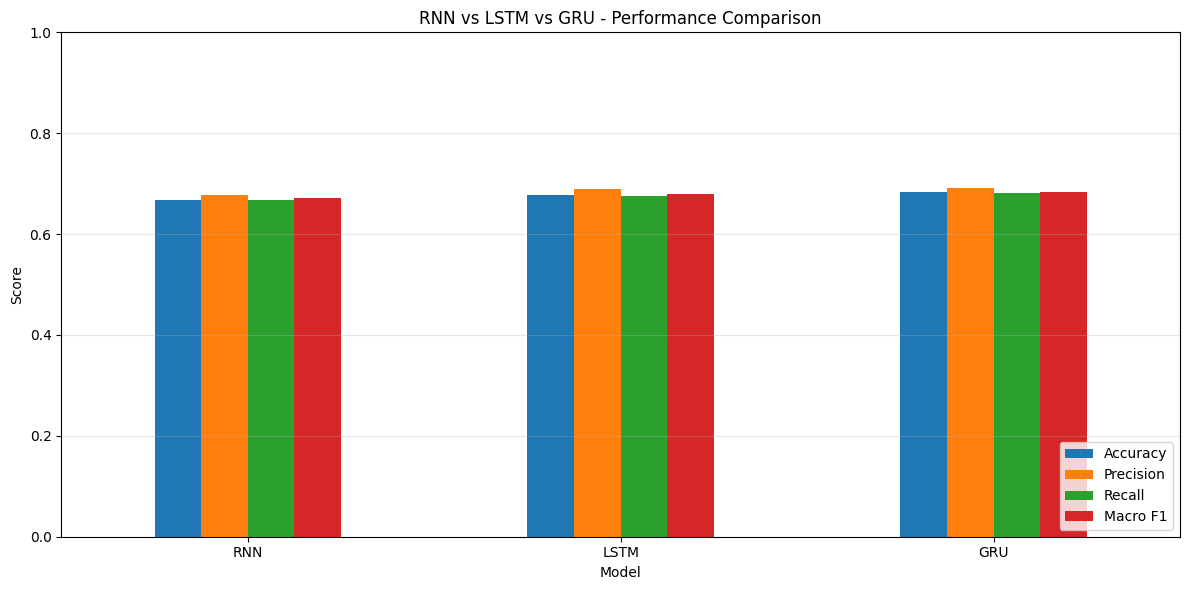

In [49]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("RNN vs LSTM vs GRU - Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Plot training and validation curves

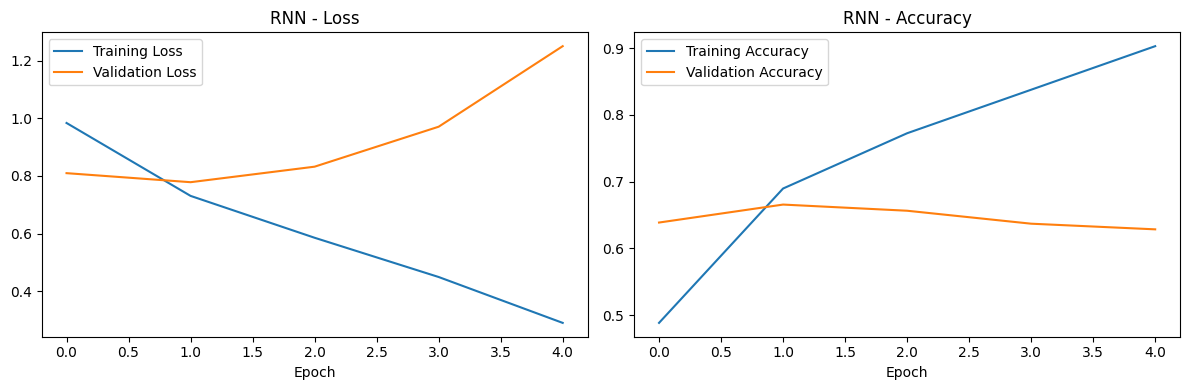

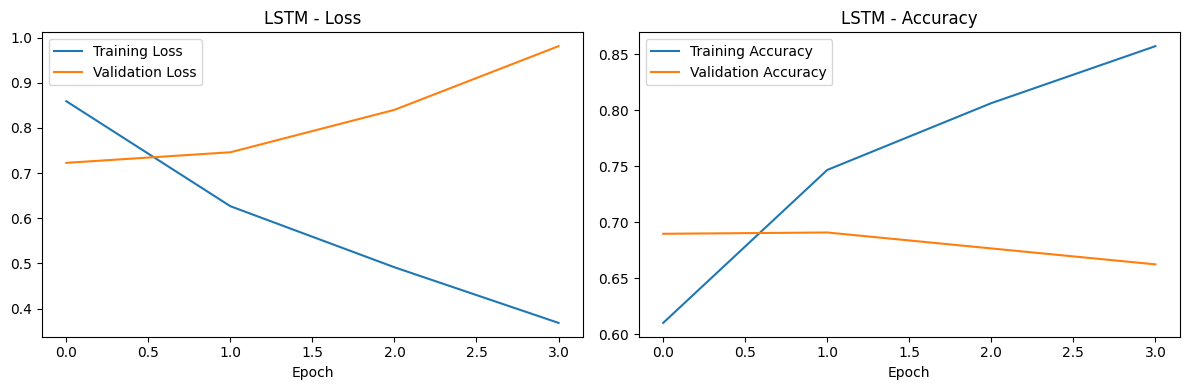

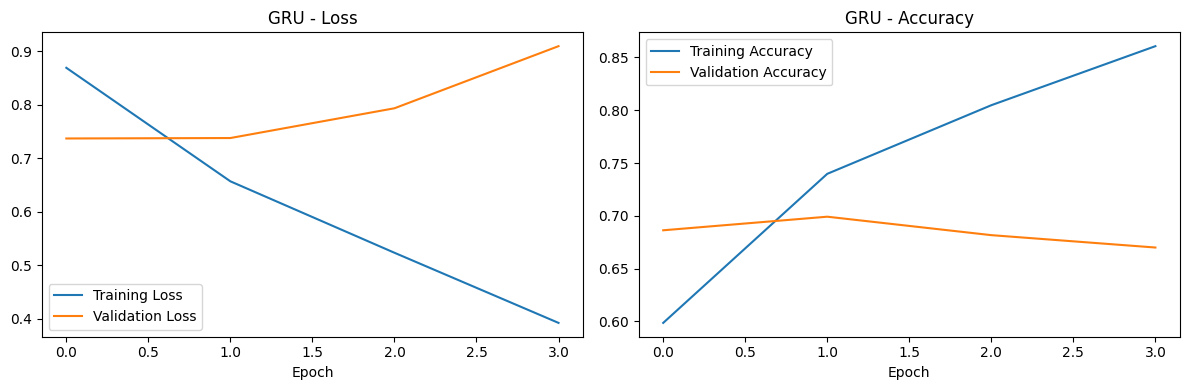

In [50]:
for model_type, history in histories.items():

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)

    plt.plot(history["loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")

    plt.title(model_type + " - Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(history["accuracy"], label="Training Accuracy")
    plt.plot(history["val_accuracy"], label="Validation Accuracy")

    plt.title(model_type + " - Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()

Confusion matrices

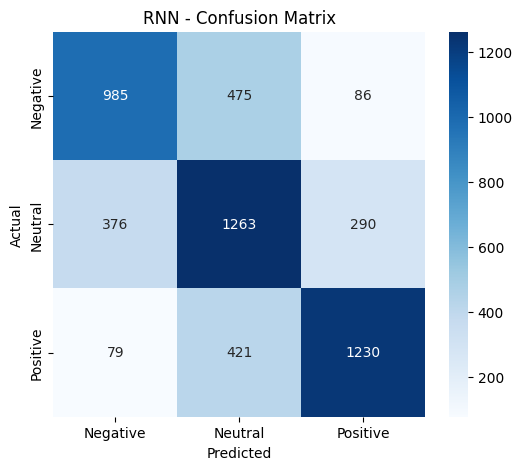


 RNN Classification Report
              precision    recall  f1-score   support

    Negative       0.68      0.64      0.66      1546
     Neutral       0.58      0.65      0.62      1929
    Positive       0.77      0.71      0.74      1730

    accuracy                           0.67      5205
   macro avg       0.68      0.67      0.67      5205
weighted avg       0.67      0.67      0.67      5205



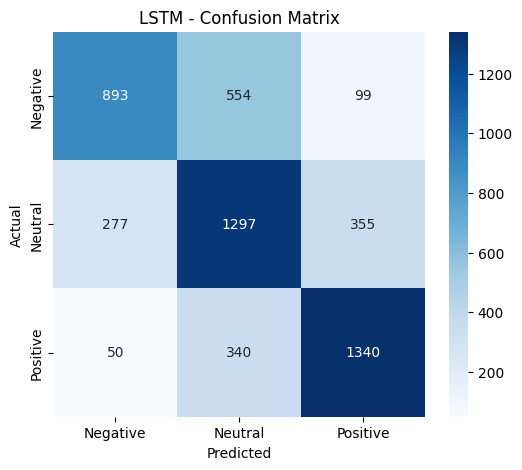


 LSTM Classification Report
              precision    recall  f1-score   support

    Negative       0.73      0.58      0.65      1546
     Neutral       0.59      0.67      0.63      1929
    Positive       0.75      0.77      0.76      1730

    accuracy                           0.68      5205
   macro avg       0.69      0.67      0.68      5205
weighted avg       0.69      0.68      0.68      5205



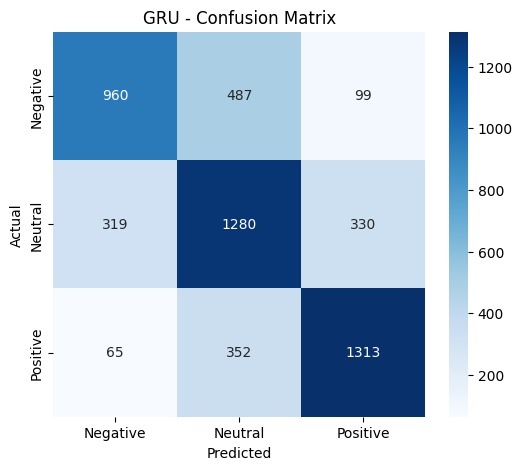


 GRU Classification Report
              precision    recall  f1-score   support

    Negative       0.71      0.62      0.66      1546
     Neutral       0.60      0.66      0.63      1929
    Positive       0.75      0.76      0.76      1730

    accuracy                           0.68      5205
   macro avg       0.69      0.68      0.68      5205
weighted avg       0.69      0.68      0.68      5205



In [51]:
class_names = ["Negative", "Neutral", "Positive"]

for model_type, model in final_models.items():

    predictions = model.predict(
        X_test,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    cm = confusion_matrix(
        y_test,
        predicted_labels
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(model_type + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print("\n", model_type, "Classification Report")

    print(
        classification_report(
            y_test,
            predicted_labels,
            target_names=class_names,
            zero_division=0
        )
    )

Identify and save the best model

In [52]:
best_model_name = results_df.loc[
    results_df["Macro F1"].idxmax(),
    "Model"
]

best_model = final_models[best_model_name]

print("Best Model:", best_model_name)
print("Best Parameters:", best_params[best_model_name])

best_model.save(
    f"best_{best_model_name.lower()}_sentiment.keras"
)

results_df.to_csv(
    "sentiment_model_comparison.csv",
    index=False
)

print("Model and comparison results saved!")

Best Model: GRU
Best Parameters: {'embedding_dim': 128, 'units': 32, 'recurrent_layers': 2, 'dense_units': 32, 'dropout': 0.30000000000000004, 'learning_rate': 0.001}
Model and comparison results saved!
